# 04 - Fine-tune IndoBERTweet (negatif / positif) - versi eksperimen v3

Perubahan dari versi sebelumnya:
- **Saklar eksperimen:** `SYN_MODE` = `none` (hanya asli) | `generic` (412 sintetis umum) | `targeted` (asli + `targeted_positives.csv` dari notebook 03b) | `both`, dan `CLASS_WEIGHT` (loss berbobot kelas).
- **Tiap run punya folder sendiri** (`model_indobertweet/<nama_run>/`), jadi tidak saling menimpa.
- **Sweep multi-seed otomatis** (dengan jeda pendinginan antar run) + **tabel perbandingan** mean ± std. Satu run saja tidak cukup, test positif cuma 51.
- **Bootstrap 95% CI** untuk macro-F1 dan recall positif.
- **Confusion matrix train + test**, analisis error + threshold, **cek kebocoran kata kunci** (mis. "mbg"), laporan **slice** `mbg`/`?` pada test, dan **uji pasangan minimal** (kalimat sama, topik diganti).
- Val split dikunci (`VAL_SEED`) supaya val sama di semua run; test set tidak disentuh untuk memilih model.

Alur: setup torch (sekali) -> config -> helper -> `run_experiment` -> satu run / sweep -> bandingkan -> analisis.

## Setup torch CUDA (sekali saja; otomatis dilewati kalau sudah terpasang)

In [1]:
import sys, re, subprocess

def _torch_ok():
    try:
        import torch
        return torch.cuda.is_available()
    except Exception:
        return False

def pip_install_with_bar(tag):
    from tqdm.auto import tqdm
    p = subprocess.Popen(
        [sys.executable, "-m", "pip", "install", "torch",
         "--index-url", f"https://download.pytorch.org/whl/{tag}", "--progress-bar", "raw"],
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    bar, last, name = None, 0, "download"
    for line in p.stdout:
        line = line.strip()
        m = re.match(r"Progress (\d+) of (\d+)", line)
        if m:
            done, total = int(m[1]), int(m[2])
            if bar is None or bar.total != total:
                if bar: bar.close()
                bar, last = tqdm(total=total, unit="B", unit_scale=True, unit_divisor=1024, desc=name), 0
            bar.update(done - last); last = done
        else:
            if line.startswith("Downloading"): name = line.split("/")[-1].split()[0][:35]
            if line.startswith(("Collecting", "Downloading", "Installing", "Successfully", "ERROR", "error")):
                tqdm.write(line[:160])
    if bar: bar.close()
    p.wait(); return p.returncode

if _torch_ok():
    import torch
    print("torch CUDA sudah terpasang:", torch.__version__, "- install dilewati")
else:
    for tag in ["cu126", "cu128", "cu121"]:
        print(f"\n=== coba {tag} ===")
        if pip_install_with_bar(tag) == 0:
            print("BERHASIL dengan", tag, "- RESTART KERNEL lalu jalankan dari cell berikutnya"); break
        print(f"{tag} gagal, coba berikutnya...")

torch CUDA sudah terpasang: 2.14.1+cu126 - install dilewati


## 1. Konfigurasi

In [2]:
import os, re, json, random, time, gc, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np, pandas as pd, torch, emoji
from torch.optim import AdamW
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, roc_auc_score, classification_report)
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

# ====== MODEL & TRAINING ======
MODEL_NAME  = "indolem/indobertweet-base-uncased"
EPOCHS, LR  = 3, 2e-5
MAX_LEN     = 96
BATCH_SIZE  = 8           # kecil = VRAM & panas lebih rendah
GRAD_ACCUM  = 2           # batch efektif = 16
WARMUP_RATIO = 0.1
SEED        = 42          # seed inisialisasi classifier & shuffle
VAL_SEED    = 42          # seed split validasi -> JANGAN diubah antar run (val harus sama)

# ====== EKSPERIMEN ======
SYN_MODE      = "none"    # "none" | "generic" | "targeted" | "both"
CLASS_WEIGHT  = True      # loss berbobot kelas
SWEEP_CONFIGS = [("none", True), ("targeted", True)]   # (syn_mode, class_weight); run yang sudah ada dilewati
SWEEP_SEEDS   = [42, 43, 44]
RUN_COOLDOWN  = 90        # detik istirahat GPU antar run di sweep

# ====== PENGAMAN GPU / SUHU ======
REQUIRE_GPU   = True
USE_FP16      = True
TEMP_PAUSE    = 78        # >= ini: jeda sampai turun
TEMP_RESUME   = 72        # lanjut kalau <= ini (harus di atas suhu idle laptop, idle kamu ~68C)
TEMP_ABORT    = 86        # >= ini: simpan lalu berhenti
STEP_SLEEP    = 0.05
EPOCH_COOLDOWN = 60
CHECK_EVERY   = 10

DATA_DIR_OVERRIDE = None
DATASET_NAME = "labels_shafwa_hans_agreement"

HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if HAS_GPU else "cpu"
if HAS_GPU:
    print("GPU :", torch.cuda.get_device_name(0), f"| VRAM {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
elif REQUIRE_GPU:
    raise SystemExit("GPU tidak terdeteksi. Jalankan cell setup torch di atas, restart kernel (atau REQUIRE_GPU=False, tidak disarankan).")
USE_FP16 = USE_FP16 and HAS_GPU

GPU : NVIDIA GeForce RTX 2060 with Max-Q Design | VRAM 6.4 GB


## 2. Cari folder data otomatis

In [3]:
def find_data_dir():
    if DATA_DIR_OVERRIDE:
        p = Path(DATA_DIR_OVERRIDE)
        if (p/"train_balanced.csv").exists(): return p
        raise FileNotFoundError(f"train_balanced.csv tidak ada di {p}")
    here = Path.cwd().resolve()
    found = []
    for base in [here] + list(here.parents):
        root = base / "data" / "praprocessing"
        if root.is_dir():
            found += [d for d in root.iterdir()
                      if (d/"train_balanced.csv").exists() and (d/"test_final.csv").exists()]
        if found: break
    if not found:
        found = [p.parent for p in here.rglob("train_balanced.csv") if (p.parent/"test_final.csv").exists()]
    if not found:
        raise FileNotFoundError("train_balanced.csv tidak ketemu. Jalankan notebook 03 dulu atau isi DATA_DIR_OVERRIDE.\n"
                                f"Folder kerja: {here}")
    pref = [d for d in found if d.name == DATASET_NAME]
    return pref[0] if pref else max(found, key=lambda d: (d/"train_balanced.csv").stat().st_mtime)

DATA_DIR  = find_data_dir()
MODEL_DIR = DATA_DIR / "model_indobertweet"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
print("DATA_DIR :", DATA_DIR)

DATA_DIR : C:\Users\nesha\VSCODE_ALL\PBAAnalysisSentiment\data\praprocessing\labels_shafwa_hans_agreement


## 3. Helper data & metrik (tanpa torch)

In [4]:
label2id = {"negatif": 0, "positif": 1}
id2label = {v: k for k, v in label2id.items()}

def prep(t):
    t = str(t).lower()
    t = re.sub(r"https?://\S+|www\.\S+", "HTTPURL", t)
    t = re.sub(r"@\w+", "@USER", t)
    try:    t = emoji.demojize(t, language="id")
    except Exception: t = emoji.demojize(t)
    return re.sub(r"\s+", " ", t).strip()

def run_name(syn_mode, class_weight, seed):
    tag = {"none": "real", "generic": "synth", "targeted": "targ", "both": "both"}[syn_mode]
    return f"{tag}_{'cw' if class_weight else 'nocw'}_s{seed}"

def load_targeted():
    """Positif targeted dari notebook 03b (hanya baris dipakai==1). Kosong kalau file belum ada."""
    f = DATA_DIR / "targeted_positives.csv"
    if not f.exists(): return pd.DataFrame(columns=["comment_text", "final_label", "sumber"])
    d = pd.read_csv(f, encoding="utf-8-sig")
    if "dipakai" in d.columns: d = d[d["dipakai"] == 1]
    d = d[["comment_text", "final_label"]].copy(); d["sumber"] = "targeted"
    return d.reset_index(drop=True)

def load_data(syn_mode="generic"):
    """Val SELALU sama (diambil dari data asli dengan VAL_SEED). syn_mode menentukan data tambahan di TRAIN."""
    assert syn_mode in ("none", "generic", "targeted", "both"), syn_mode
    tr = pd.read_csv(DATA_DIR/"train_balanced.csv", encoding="utf-8")
    te = pd.read_csv(DATA_DIR/"test_final.csv",  encoding="utf-8")
    if "sumber" not in tr.columns: tr["sumber"] = "asli"
    for d in (tr, te):
        d["label"] = d["final_label"].map(label2id)
        d["text"]  = d["comment_text"].map(prep)
    real = tr[tr["sumber"] == "asli"]
    val = pd.concat([real[real["label"] == k].sample(frac=0.12, random_state=VAL_SEED) for k in (0, 1)])
    tr = tr.drop(val.index)
    tg = load_targeted()
    if len(tg):
        tg["label"] = tg["final_label"].map(label2id); tg["text"] = tg["comment_text"].map(prep)
        banned = [set(re.findall(r"\w+|\?", x)) for x in list(val["comment_text"].map(prep)) + list(te["text"])]
        def _too_close(t, thr=0.7):      # buang yang identik ATAU sangat mirip dengan val/test
            ts = set(re.findall(r"\w+|\?", t))
            return any(len(ts & bb) / max(len(ts | bb), 1) >= thr for bb in banned)
        close = tg["text"].map(_too_close)
        if close.any(): print(f"[load_data] {int(close.sum())} baris targeted dibuang karena mirip val/test")
        tg = tg[~close]
    tr = pd.concat([tr, tg], ignore_index=True)
    keep = {"none": [], "generic": ["synthetic"], "targeted": ["targeted"], "both": ["synthetic", "targeted"]}[syn_mode]
    tr = tr[(tr["sumber"] == "asli") | tr["sumber"].isin(keep)]
    return tr.reset_index(drop=True), val.reset_index(drop=True), te.reset_index(drop=True)

def metrics_from_preds(y, p, prob):
    cm = confusion_matrix(y, p, labels=[0, 1])
    return {"test_acc": float(accuracy_score(y, p)),
            "test_macro_f1": float(precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]),
            "test_auc": float(roc_auc_score(y, prob)),
            "recall_pos": float(cm[1, 1] / max(cm[1].sum(), 1)),
            "precision_pos": float(cm[1, 1] / max(cm[:, 1].sum(), 1)),
            "recall_neg": float(cm[0, 0] / max(cm[0].sum(), 1)),
            "confusion_matrix": cm.tolist()}

def bootstrap_ci(y, p, n=1000, seed=0):
    """Interval 95% (bootstrap atas komentar test) untuk macro-F1 dan recall positif."""
    rng = np.random.RandomState(seed); idx = np.arange(len(y)); mf, rp = [], []
    for _ in range(n):
        s = rng.choice(idx, len(idx), replace=True); ys, ps = y[s], p[s]
        mf.append(precision_recall_fscore_support(ys, ps, average="macro", zero_division=0)[2])
        if (ys == 1).any(): rp.append((ps[ys == 1] == 1).mean())
    return {"macro_f1_ci": [float(x) for x in np.percentile(mf, [2.5, 97.5])],
            "recall_pos_ci": [float(x) for x in np.percentile(rp, [2.5, 97.5])]}

_tr, _va, _te = load_data("both")
print("Train (mode both):", len(_tr), dict(_tr["final_label"].value_counts()), "| sumber:", dict(_tr["sumber"].value_counts()))
print("Val  :", len(_va), dict(_va["final_label"].value_counts()))
print("Test :", len(_te), dict(_te["final_label"].value_counts()))
print("\nContoh preprocessing (emoji harus jadi teks):")
for t in _tr["text"].head(3): print(" -", t[:120])
del _tr, _va, _te

Train (mode both): 1449 {'positif': np.int64(789), 'negatif': np.int64(660)} | sumber: {'asli': np.int64(957), 'synthetic': np.int64(412), 'targeted': np.int64(80)}
Val  : 131 {'negatif': np.int64(90), 'positif': np.int64(41)}
Test : 446 {'negatif': np.int64(395), 'positif': np.int64(51)}

Contoh preprocessing (emoji harus jadi teks):
 - masalahnya jangan dipaksakan, biar bagaimanapun prabowo tetap keren :wajah_berkacamata_hitam:
 - sukses selalu untuk prabowo:berkilau:
 - sumpah unik malah buka kartu :tertawa_terbahak-bahak::tertawa_terbahak-bahak:


## 4. Helper torch (tokenizer, loader, predict, pengaman suhu)

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class DS(Dataset):
    def __init__(self, df):
        enc = tokenizer(df["text"].tolist(), max_length=MAX_LEN, truncation=True)   # tanpa padding
        self.ids, self.y = enc["input_ids"], df["label"].tolist()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.ids[i], self.y[i]

def collate(batch):
    L = max(len(x) for x, _ in batch); pad = tokenizer.pad_token_id
    return {"input_ids": torch.tensor([x + [pad]*(L-len(x)) for x, _ in batch]),
            "attention_mask": torch.tensor([[1]*len(x) + [0]*(L-len(x)) for x, _ in batch]),
            "labels": torch.tensor([y for _, y in batch])}

def make_loader(df, bs, shuffle=False, seed=SEED):
    gen = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(DS(df), batch_size=bs, shuffle=shuffle, collate_fn=collate, num_workers=0, generator=gen)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if HAS_GPU: torch.cuda.manual_seed_all(s)

@torch.no_grad()
def predict(model, loader):
    model.eval(); ys, ps, pr = [], [], []
    for b in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
            out = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE))
        prob = torch.softmax(out.logits.float(), dim=1).cpu().numpy()
        ys += b["labels"].tolist(); ps += prob.argmax(1).tolist(); pr += prob[:, 1].tolist()
    return np.array(ys), np.array(ps), np.array(pr)

def gpu_temp():
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=temperature.gpu", "--format=csv,noheader,nounits"],
                             capture_output=True, text=True, timeout=5).stdout.strip().splitlines()
        return int(out[0])
    except Exception:
        return None

class ThermalAbort(Exception): pass

def thermal_guard():
    t = gpu_temp()
    if t is None: return
    if t >= TEMP_ABORT: raise ThermalAbort(f"GPU {t}C >= {TEMP_ABORT}C, berhenti demi keamanan")
    if t >= TEMP_PAUSE:
        print(f"\n  GPU {t}C, jeda sampai <= {TEMP_RESUME}C ...", end="")
        torch.cuda.empty_cache()
        while True:
            time.sleep(10); t = gpu_temp()
            if t is None or t <= TEMP_RESUME: break
            if t >= TEMP_ABORT: raise ThermalAbort(f"GPU {t}C saat jeda")
        print(f" lanjut ({t}C)")

print("Suhu GPU sekarang:", gpu_temp(), "C  (None = nvidia-smi tidak terbaca, pengaman suhu nonaktif)")

Suhu GPU sekarang: 58 C  (None = nvidia-smi tidak terbaca, pengaman suhu nonaktif)


## 5. `run_experiment`: satu run penuh (latih -> pilih checkpoint di val -> uji di test -> simpan)

In [6]:
def run_experiment(syn_mode="none", class_weight=False, seed=SEED):
    name = run_name(syn_mode, class_weight, seed)
    run_dir = MODEL_DIR / name; run_dir.mkdir(parents=True, exist_ok=True)
    set_seed(seed)

    train_df, val_df, test_df = load_data(syn_mode)
    train_loader = make_loader(train_df, BATCH_SIZE, True, seed)
    val_loader, test_loader = make_loader(val_df, BATCH_SIZE*2), make_loader(test_df, BATCH_SIZE*2)
    n_syn = int((train_df["sumber"] == "synthetic").sum()); n_tg = int((train_df["sumber"] == "targeted").sum())
    print(f"\n=== RUN {name} | train={len(train_df)} {dict(train_df['final_label'].value_counts())} | synthetic={n_syn} | targeted={n_tg} ===")

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id).to(DEVICE)
    w = None
    if class_weight:
        cnt = np.bincount(train_df["label"], minlength=2)
        w = torch.tensor(len(train_df) / (2 * cnt), dtype=torch.float32, device=DEVICE)
        print("bobot kelas [negatif, positif]:", w.cpu().numpy().round(3))
    loss_fn = torch.nn.CrossEntropyLoss(weight=w)

    total_steps = ((len(train_loader) + GRAD_ACCUM - 1) // GRAD_ACCUM) * EPOCHS
    opt = AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)

    best_f1, best_ep, history = -1.0, 0, []
    try:
        for ep in range(1, EPOCHS + 1):
            model.train(); tot = 0.0; opt.zero_grad()
            for i, b in enumerate(train_loader, 1):
                with torch.autocast("cuda", dtype=torch.float16, enabled=USE_FP16):
                    logits = model(input_ids=b["input_ids"].to(DEVICE), attention_mask=b["attention_mask"].to(DEVICE)).logits
                loss = loss_fn(logits.float(), b["labels"].to(DEVICE))
                scaler.scale(loss / GRAD_ACCUM).backward()
                tot += loss.item()
                if i % GRAD_ACCUM == 0 or i == len(train_loader):
                    scaler.unscale_(opt)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()
                if STEP_SLEEP: time.sleep(STEP_SLEEP)
                if HAS_GPU and i % CHECK_EVERY == 0:
                    thermal_guard()
                    print(f"\r  epoch {ep}/{EPOCHS} batch {i}/{len(train_loader)} loss {loss.item():.4f} | GPU {gpu_temp()}C   ", end="")
            y, p, _ = predict(model, val_loader)
            f1m = precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]
            history.append({"epoch": ep, "train_loss": tot / len(train_loader), "val_acc": float(accuracy_score(y, p)), "val_macro_f1": float(f1m)})
            print(f"\nEpoch {ep}: train_loss={tot/len(train_loader):.4f} | val_acc={accuracy_score(y,p):.4f} | val_macroF1={f1m:.4f}")
            if f1m > best_f1:
                best_f1, best_ep = f1m, ep
                model.save_pretrained(run_dir/"best"); tokenizer.save_pretrained(run_dir/"best")
                print("  -> checkpoint terbaik disimpan")
            if ep < EPOCHS and HAS_GPU and EPOCH_COOLDOWN:
                torch.cuda.empty_cache(); print(f"  istirahat GPU {EPOCH_COOLDOWN}s ..."); time.sleep(EPOCH_COOLDOWN)
    except ThermalAbort as e:
        model.save_pretrained(run_dir/"last"); tokenizer.save_pretrained(run_dir/"last")
        print("\n", e, "- model terakhir disimpan di", run_dir/"last"); raise
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print("\nVRAM habis. Set BATCH_SIZE=4 dan GRAD_ACCUM=4 (atau MAX_LEN=64), restart kernel, run ulang."); raise

    # evaluasi checkpoint terbaik di TEST (test tidak dipakai untuk memilih apa pun)
    del model; gc.collect()
    if HAS_GPU: torch.cuda.empty_cache()
    best_model = AutoModelForSequenceClassification.from_pretrained(run_dir/"best").to(DEVICE)
    y, p, prob = predict(best_model, test_loader)
    m = {"run": name, "syn_mode": syn_mode, "class_weight": bool(class_weight), "seed": seed,
         "n_train": len(train_df), "n_synthetic": n_syn, "n_targeted": n_tg, "n_val": len(val_df), "n_test": len(test_df),
         "best_epoch": best_ep, "val_macro_f1": float(best_f1),
         **metrics_from_preds(y, p, prob), **bootstrap_ci(y, p), "history": history,
         "epochs": EPOCHS, "lr": LR, "batch_efektif": BATCH_SIZE*GRAD_ACCUM, "max_len": MAX_LEN, "fp16": USE_FP16}
    json.dump(m, open(run_dir/"metrics.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
    pd.DataFrame({"comment_text": test_df["comment_text"], "asli": [id2label[i] for i in y],
                  "prediksi": [id2label[i] for i in p], "prob_positif": prob}
                 ).to_csv(run_dir/"test_predictions.csv", index=False, encoding="utf-8")
    print(f"TEST {name}: macro-F1={m['test_macro_f1']:.3f} (CI {m['macro_f1_ci'][0]:.2f}-{m['macro_f1_ci'][1]:.2f}) | "
          f"recall positif={m['recall_pos']:.1%} (CI {m['recall_pos_ci'][0]:.0%}-{m['recall_pos_ci'][1]:.0%}) | precision positif={m['precision_pos']:.1%}")
    del best_model; gc.collect()
    if HAS_GPU: torch.cuda.empty_cache()
    return m

## 6a. Satu run (pakai setelan di cell konfigurasi)

In [7]:
m = run_experiment(SYN_MODE, CLASS_WEIGHT, SEED)


=== RUN real_cw_s42 | train=957 {'negatif': np.int64(660), 'positif': np.int64(297)} | synthetic=0 | targeted=0 ===


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 23443.05it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing 

bobot kelas [negatif, positif]: [0.725 1.611]
  epoch 1/3 batch 120/120 loss 0.4613 | GPU 66C   
Epoch 1: train_loss=0.5446 | val_acc=0.8855 | val_macroF1=0.8576


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.42it/s]


  -> checkpoint terbaik disimpan
  istirahat GPU 60s ...
  epoch 2/3 batch 120/120 loss 0.0566 | GPU 66C   
Epoch 2: train_loss=0.2740 | val_acc=0.8779 | val_macroF1=0.8540
  istirahat GPU 60s ...
  epoch 3/3 batch 120/120 loss 0.0146 | GPU 63C   
Epoch 3: train_loss=0.1681 | val_acc=0.8931 | val_macroF1=0.8722


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.55it/s]


  -> checkpoint terbaik disimpan


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 804.22it/s]


TEST real_cw_s42: macro-F1=0.842 (CI 0.78-0.89) | recall positif=70.6% (CI 57%-83%) | precision positif=73.5%


## 6b. Sweep eksperimen (config x seed), otomatis & aman dilanjutkan
Run yang `metrics.json`-nya sudah ada **dilewati**, jadi kalau terhenti (suhu / kernel) tinggal jalankan lagi.
Default: 2 konfigurasi x 3 seed = 6 run. Ada jeda `RUN_COOLDOWN` antar run supaya GPU tidak terus-menerus penuh.

In [8]:
todo = [(syn, cw, s) for s in SWEEP_SEEDS for (syn, cw) in SWEEP_CONFIGS]
for k, (syn, cw, s) in enumerate(todo, 1):
    name = run_name(syn, cw, s)
    if (MODEL_DIR/name/"metrics.json").exists():
        print(f"[{k}/{len(todo)}] {name}: sudah ada, dilewati"); continue
    print(f"\n########## [{k}/{len(todo)}] {name} ##########")
    run_experiment(syn, cw, s)
    if HAS_GPU and k < len(todo):
        print(f"istirahat {RUN_COOLDOWN}s sebelum run berikutnya (GPU {gpu_temp()}C) ...")
        time.sleep(RUN_COOLDOWN)
print("\nSweep selesai.")

[1/6] real_cw_s42: sudah ada, dilewati

########## [2/6] targ_cw_s42 ##########

=== RUN targ_cw_s42 | train=1037 {'negatif': np.int64(660), 'positif': np.int64(377)} | synthetic=0 | targeted=80 ===


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 16352.54it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing 

bobot kelas [negatif, positif]: [0.786 1.375]
  epoch 1/3 batch 130/130 loss 0.4453 | GPU 68C   
Epoch 1: train_loss=0.5574 | val_acc=0.8473 | val_macroF1=0.8269


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.81it/s]


  -> checkpoint terbaik disimpan
  istirahat GPU 60s ...
  epoch 2/3 batch 130/130 loss 0.5261 | GPU 66C   
Epoch 2: train_loss=0.2642 | val_acc=0.8626 | val_macroF1=0.8477


...

  -> checkpoint terbaik disimpan
  istirahat GPU 60s ...
  epoch 2/3 batch 130/130 loss 0.7745 | GPU 66C   
Epoch 2: train_loss=0.3176 | val_acc=0.9084 | val_macroF1=0.8920


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.20it/s]


  -> checkpoint terbaik disimpan
  istirahat GPU 60s ...
  epoch 3/3 batch 130/130 loss 0.2430 | GPU 66C   
Epoch 3: train_loss=0.1901 | val_acc=0.8855 | val_macroF1=0.8694


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1020.05it/s]


TEST targ_cw_s44: macro-F1=0.807 (CI 0.74-0.86) | recall positif=70.6% (CI 58%-83%) | precision positif=62.1%

Sweep selesai.


## 7. Bandingkan semua run
Perbedaan antar konfigurasi baru bermakna kalau lebih besar dari `std` antar seed **dan** CI-nya tidak tumpang-tindih besar. Test positif cuma 51, jadi hati-hati menyimpulkan dari selisih kecil.

In [9]:
rows = [json.load(open(f, encoding="utf-8")) for f in sorted(MODEL_DIR.glob("*/metrics.json"))]
res = pd.DataFrame(rows)
if not res.empty:      # kompatibel dengan run lama (yang memakai use_synthetic bool)
    legacy = res["use_synthetic"].map({True: "generic", False: "none"}) if "use_synthetic" in res else None
    if "syn_mode" not in res: res["syn_mode"] = legacy
    elif legacy is not None: res["syn_mode"] = res["syn_mode"].fillna(legacy)
    if "n_targeted" not in res: res["n_targeted"] = 0
    res["n_targeted"] = res["n_targeted"].fillna(0).astype(int)
if res.empty:
    print("Belum ada run.")
else:
    cols = ["run", "syn_mode", "n_train", "n_synthetic", "n_targeted", "best_epoch", "val_macro_f1", "test_macro_f1", "recall_pos", "precision_pos", "recall_neg", "test_auc"]
    print(res[cols].round(3).to_string(index=False))
    print("\nRingkasan per konfigurasi (mean +- std antar seed):")
    summ = (res.groupby(["syn_mode", "class_weight"])
               .agg(n_run=("seed", "count"),
                    macroF1_mean=("test_macro_f1", "mean"), macroF1_std=("test_macro_f1", "std"),
                    recall_pos_mean=("recall_pos", "mean"), recall_pos_std=("recall_pos", "std"),
                    precision_pos_mean=("precision_pos", "mean")).round(3))
    print(summ.to_string())
    if res["seed"].nunique() < 2:
        print("\n(Baru 1 seed: belum bisa menilai variasi antar run. Jalankan sweep.)")

           run syn_mode  n_train  n_synthetic  n_targeted  best_epoch  val_macro_f1  test_macro_f1  recall_pos  precision_pos  recall_neg  test_auc
   real_cw_s42     none      957            0           0           3         0.872          0.842       0.706          0.735       0.967     0.938
   real_cw_s43     none      957            0           0           3         0.868          0.828       0.745          0.655       0.949     0.905
   real_cw_s44     none      957            0           0           3         0.874          0.839       0.745          0.691       0.957     0.929
synth_nocw_s42  generic     1369          412           0           3         0.887          0.822       0.706          0.667       0.954     0.946
synth_nocw_s43  generic     1369          412           0           2         0.893          0.793       0.686          0.593       0.939     0.914
synth_nocw_s44  generic     1369          412           0           2         0.887          0.806       0.725  

## 8. Confusion matrix TRAIN + TEST untuk satu run

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1238.72it/s]


TRAIN: acc=0.9666 | macro-F1=0.9606 | recall negatif=98.2% | recall positif=93.3%
TEST : acc=0.9372 | macro-F1=0.8423 | recall negatif=96.7% | recall positif=70.6%


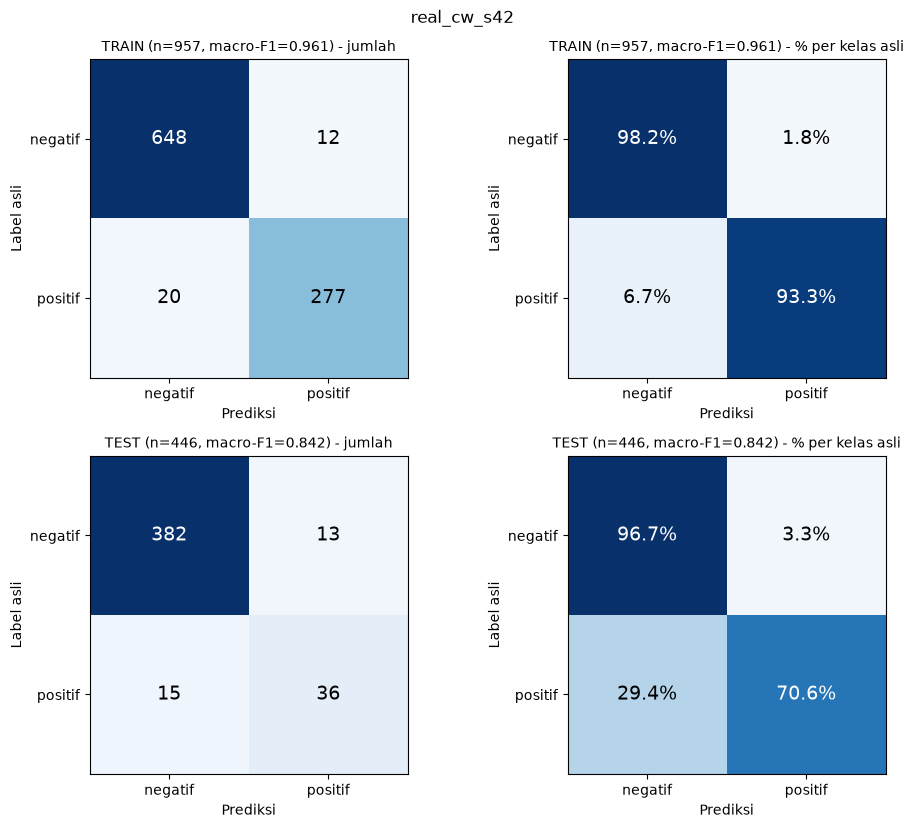

Train [asli     ] n= 957 | akurasi=96.7%


In [10]:
def plot_run(name):
    import matplotlib.pyplot as plt
    run_dir = MODEL_DIR / name
    info = json.load(open(run_dir/"metrics.json", encoding="utf-8"))
    train_df, val_df, test_df = load_data(info.get("syn_mode") or ("generic" if info.get("use_synthetic") else "none"))
    model = AutoModelForSequenceClassification.from_pretrained(run_dir/"best").to(DEVICE)
    names = ["negatif", "positif"]
    res = {"TRAIN": predict(model, make_loader(train_df, BATCH_SIZE*2))[:2],
           "TEST":  predict(model, make_loader(test_df,  BATCH_SIZE*2))[:2]}
    fig, axes = plt.subplots(2, 2, figsize=(10, 8.4))
    for r, (nama, (y, p)) in enumerate(res.items()):
        cm  = confusion_matrix(y, p, labels=[0, 1]); cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
        mf1 = precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]
        for c, (data, title, fmt) in enumerate(((cm, "jumlah", "d"), (cmn, "% per kelas asli", ".1%"))):
            ax = axes[r, c]; ax.imshow(data, cmap="Blues", vmin=0, vmax=data.max())
            ax.set_xticks([0, 1], names); ax.set_yticks([0, 1], names)
            ax.set_xlabel("Prediksi"); ax.set_ylabel("Label asli")
            ax.set_title(f"{nama} (n={len(y)}, macro-F1={mf1:.3f}) - {title}", fontsize=10)
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, format(data[i, j], fmt), ha="center", va="center", fontsize=14,
                            color="white" if data[i, j] > data.max()/2 else "black")
        print(f"{nama:5s}: acc={accuracy_score(y, p):.4f} | macro-F1={mf1:.4f} | recall negatif={cmn[0,0]:.1%} | recall positif={cmn[1,1]:.1%}")
    fig.suptitle(name); fig.tight_layout()
    fig.savefig(run_dir/"confusion_matrix_train_test.png", dpi=150); plt.show()
    y_tr, p_tr = res["TRAIN"]
    for s in ("asli", "synthetic", "targeted"):
        mk_ = (train_df["sumber"] == s).values
        if mk_.any(): print(f"Train [{s:9s}] n={mk_.sum():4d} | akurasi={accuracy_score(y_tr[mk_], p_tr[mk_]):.1%}")
    del model; gc.collect()
    if HAS_GPU: torch.cuda.empty_cache()

RUN_TO_INSPECT = run_name(SYN_MODE, CLASS_WEIGHT, SEED)   # ganti kalau mau run lain
plot_run(RUN_TO_INSPECT)

## 9. Analisis error + threshold (untuk satu run)

In [11]:
def show_errors(name, top=20):
    pred = pd.read_csv(MODEL_DIR/name/"test_predictions.csv", encoding="utf-8")
    is_pos = pred["asli"] == "positif"
    pd.set_option("display.max_colwidth", 130); pd.set_option("display.width", 250)
    print("prob_positif untuk positif asli:"); print(pred.loc[is_pos, "prob_positif"].describe().round(3))
    print("\nPositif asli yang diprediksi negatif:")
    print(pred[is_pos & (pred["prediksi"] == "negatif")].sort_values("prob_positif")[["comment_text", "prob_positif"]].head(top).to_string())
    print("\nNegatif asli yang diprediksi positif:")
    print(pred[~is_pos & (pred["prediksi"] == "positif")].sort_values("prob_positif", ascending=False)[["comment_text", "prob_positif"]].head(top).to_string())
    print("\nKalau threshold diturunkan:")
    for t in (0.5, 0.4, 0.3, 0.2, 0.1):
        hit = pred["prob_positif"] >= t
        tp = (is_pos & hit).sum(); fp = (~is_pos & hit).sum()
        print(f"  threshold {t}: recall={tp/is_pos.sum():.1%} | precision={tp/max(tp+fp,1):.1%} | salah-positif={fp}")

show_errors(RUN_TO_INSPECT)

prob_positif untuk positif asli:
count    51.000
mean      0.681
std       0.356
min       0.007
25%       0.342
50%       0.893
75%       0.968
max       0.997
Name: prob_positif, dtype: float64

Positif asli yang diprediksi negatif:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

## 10. Cek kebocoran kata kunci di data latih
Kalau satu kata (mis. "mbg") hampir selalu muncul di satu label, model bisa belajar "ada kata itu -> label itu" tanpa membaca isi kalimat.

In [12]:
KEYWORDS = ["mbg", "sppg", "dukung", "bagus", "?", "korup", "hutang"]
tr_all, va_all, _ = load_data("both")
tr_all = pd.concat([tr_all, va_all])
for sumber_filter, judul in ((None, "SEMUA data latih (asli + sintetis + targeted)"), ("asli", "hanya data ASLI"), ("targeted", "hanya TARGETED")):
    d = tr_all if sumber_filter is None else tr_all[tr_all["sumber"] == sumber_filter]
    if len(d) == 0: continue
    print(f"\n{judul} (n={len(d)}, % positif keseluruhan = {d['label'].mean():.0%})")
    for kw in KEYWORDS:
        m_ = d["text"].str.contains(kw, regex=False)
        if m_.sum(): print(f"  {kw!r:9}: {m_.sum():4d} komentar | % positif = {d.loc[m_, 'label'].mean():.0%}")
print("\nKomposisi asli vs synthetic:")
print(tr_all.groupby(["sumber", "final_label"]).size().unstack(fill_value=0))


SEMUA data latih (asli + sintetis + targeted) (n=1580, % positif keseluruhan = 53%)
  'mbg'    :  170 komentar | % positif = 51%
  'sppg'   :    1 komentar | % positif = 0%
  'dukung' :   53 komentar | % positif = 85%
  'bagus'  :   15 komentar | % positif = 80%
  '?'      :   87 komentar | % positif = 30%
  'korup'  :   27 komentar | % positif = 52%

hanya data ASLI (n=1088, % positif keseluruhan = 31%)
  'mbg'    :   92 komentar | % positif = 9%
  'sppg'   :    1 komentar | % positif = 0%
  'dukung' :   27 komentar | % positif = 70%
  'bagus'  :    6 komentar | % positif = 50%
  '?'      :   67 komentar | % positif = 9%
  'korup'  :   26 komentar | % positif = 50%

hanya TARGETED (n=80, % positif keseluruhan = 100%)
  'mbg'    :   77 komentar | % positif = 100%
  'dukung' :    8 komentar | % positif = 100%
  'bagus'  :    3 komentar | % positif = 100%
  '?'      :   16 komentar | % positif = 100%

Komposisi asli vs synthetic:
final_label  negatif  positif
sumber                     

## 11. Laporan slice pada TEST: komentar yang memuat `mbg` / `?`
Jumlahnya kecil (lihat kolom n), jadi lihat arah, jangan ambil kesimpulan dari satu angka.

In [13]:
def slice_report(names=None, keywords=("mbg", "?")):
    names = names or sorted(p.parent.name for p in MODEL_DIR.glob("*/test_predictions.csv"))
    for kw in keywords:
        print(f"\n--- slice '{kw}' di test ---")
        for name in names:
            pred = pd.read_csv(MODEL_DIR/name/"test_predictions.csv", encoding="utf-8")
            sub = pred[pred["comment_text"].str.lower().str.contains(kw, regex=False)]
            pos, neg = sub[sub["asli"] == "positif"], sub[sub["asli"] == "negatif"]
            rp = (pos["prediksi"] == "positif").mean() if len(pos) else float("nan")
            rn = (neg["prediksi"] == "negatif").mean() if len(neg) else float("nan")
            print(f"{name:16s} n={len(sub):3d} | positif asli={len(pos):2d} recall={rp:5.0%} | negatif asli={len(neg):3d} recall={rn:5.0%}")
slice_report()


--- slice 'mbg' di test ---
real_cw_s42      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
real_cw_s43      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
real_cw_s44      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
synth_nocw_s42   n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
synth_nocw_s43   n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
synth_nocw_s44   n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall= 100%
targ_cw_s42      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall=  94%
targ_cw_s43      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall=  94%
targ_cw_s44      n= 32 | positif asli= 1 recall=   0% | negatif asli= 31 recall=  90%

--- slice '?' di test ---
real_cw_s42      n= 39 | positif asli= 6 recall=  67% | negatif asli= 33 recall=  97%
real_cw_s43      n= 39 | positif asli= 6 recall=  83% | negatif asli= 33 recall=  97

## 12. Uji pasangan minimal: kalimat yang sama, hanya topik diganti
Kalau `mbg` jauh lebih rendah dari topik lain padahal kalimatnya identik, model membaca topik, bukan sikap.
Bandingkan beberapa run sekaligus (mis. `real_cw_s42` vs `targ_cw_s42`).

In [14]:
def minimal_pair(names, topics=("mbg", "program ini", "infrastruktur", "ekonomi", "pendidikan", "bansos"),
                 templates=("{} bagus banget, saya dukung", "dukung {}, bermanfaat", "{} sangat membantu rakyat", "{} program bagus")):
    table = {}
    for name in names:
        if not (MODEL_DIR/name/"best").exists(): print("lewati (belum ada):", name); continue
        mdl = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR/name/"best").to(DEVICE).eval()
        col = {}
        for tp in topics:
            ps = []
            for tpl in templates:
                e = tokenizer(prep(tpl.format(tp)), max_length=MAX_LEN, truncation=True, return_tensors="pt").to(DEVICE)
                with torch.no_grad(): ps.append(float(torch.softmax(mdl(**e).logits.float(), dim=1)[0, 1]))
            col[tp] = np.mean(ps)
        table[name] = col
        del mdl; gc.collect()
        if HAS_GPU: torch.cuda.empty_cache()
    out = pd.DataFrame(table).round(2)
    print("Rata-rata P(positif) per topik (4 template kalimat pendukung):"); print(out.to_string())
    return out

_ = minimal_pair([run_name("none", True, SEED), run_name("targeted", True, SEED)])

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1271.57it/s]


Rata-rata P(positif) per topik (4 template kalimat pendukung):
               real_cw_s42  targ_cw_s42
mbg                   0.07         0.72
program ini           0.25         0.63
infrastruktur         0.23         0.58
ekonomi               0.39         0.63
pendidikan            0.30         0.67
bansos                0.26         0.63


## 13. Coba komentar sendiri

In [15]:
def predict_text(model, t):
    model.eval()
    e = tokenizer(prep(t), max_length=MAX_LEN, truncation=True, return_tensors="pt").to(DEVICE)
    with torch.no_grad(): pr = torch.softmax(model(**e).logits.float(), dim=1)[0].cpu().numpy()
    return id2label[int(pr.argmax())], round(float(pr.max()), 3)

_m = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR/RUN_TO_INSPECT/"best").to(DEVICE)
for t in ["Pak Prabowo memang tegas, mantap 🇮🇩👏", "MBG bermanfaat atau tidakk??", "Dukung MBG bermanfaat",
          "mbg program bagus", "bagus programnya, semoga jalan", "tetep aja salah kalau di mata pembenci"]:
    print(predict_text(_m, t), "|", t)
del _m; gc.collect()
if HAS_GPU: torch.cuda.empty_cache()

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1140.57it/s]


('positif', 0.99) | Pak Prabowo memang tegas, mantap 🇮🇩👏
('negatif', 0.994) | MBG bermanfaat atau tidakk??
('negatif', 0.973) | Dukung MBG bermanfaat
('negatif', 0.99) | mbg program bagus
('negatif', 0.807) | bagus programnya, semoga jalan
('negatif', 0.913) | tetep aja salah kalau di mata pembenci
